# 02 — CV Harness + First LightGBM

**Goal:** build the validation setup we will trust for the rest of the competition, then fit a first, deliberately-untuned LightGBM and calibrate our CV score against the public leaderboard.

## 1. Why CV before models

Every experiment from here on — every feature, every hyperparameter — will be judged by one number. If that number is noisy or biased, we'll spend two weeks chasing ghosts. Hence the order: **validation scheme first, models second.**

Why not just use the public leaderboard as the judge? Three reasons:

1. **It's a limited resource** (5 submissions/day) — you can't run 8 experiments a day against it.
2. **It's a sample, not the truth.** The public LB is scored on a fraction of the test set. Optimizing against it is fitting noise, and Playground competitions regularly see public-LB heroes drop on the private LB ("shakeup").
3. **You leak information every time you peek.** Each LB-driven decision subtly fits the public split.

The public LB's proper role: an occasional *calibration check* that our CV isn't lying — which is exactly what §6 does. Notebook 01 found zero train/test drift, so we should expect a tight CV↔LB agreement; a large gap would mean a bug in *our* pipeline, not the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

TARGET = 'health_condition'
NUM = ['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure',
       'step_count', 'exercise_duration', 'water_intake']
CAT = ['diet_type', 'stress_level', 'sleep_quality',
       'physical_activity_level', 'smoking_alcohol', 'gender']
FEATURES = NUM + CAT
SEED = 42

# Label mapping: fixed and explicit, so class indices mean the same thing everywhere.
CLASSES = ['at-risk', 'fit', 'unhealthy']  # alphabetical, matches sorted()
cls_to_idx = {c: i for i, c in enumerate(CLASSES)}
y = train[TARGET].map(cls_to_idx).to_numpy()

# LightGBM's native categorical handling wants pandas 'category' dtype.
X = train[FEATURES].copy()
X_test = test[FEATURES].copy()
for c in CAT:
    X[c] = X[c].astype('category')
    # Align test categories to train's — same codes on both sides.
    X_test[c] = X_test[c].astype(pd.CategoricalDtype(X[c].cat.categories))

print(X.shape, X_test.shape, np.bincount(y) / len(y))

(690088, 13) (295753, 13) [0.85867455 0.05767815 0.0836473 ]


## 2. Choosing the CV scheme

The scheme must answer one question: *how do we split so that validation mimics the train→test relationship?*

- **No groups** (no student appears twice — rows are independent) → `GroupKFold` unnecessary.
- **No time order** (synthetic tabular data, no timestamps) → `TimeSeriesSplit` unnecessary.
- **Imbalanced target + balanced-accuracy metric** → **stratification is critical.** Balanced accuracy averages per-class recalls, and `fit` recall in a fold is estimated from only ~8,000 rows (39,803 / 5). Without stratification, fold-to-fold class proportions would wobble and add pure noise to exactly the number we care about.

So: `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

**Why 5 folds and not 10?** 10 folds halves the per-fold validation set (noisier per-fold scores, but more of them) and doubles runtime. At 690k rows, 5 folds gives ~138k validation rows per fold — plenty — at half the cost. The binding constraint here is experiment *throughput*: a cheaper CV loop means more hypotheses tested per day.

**One more rule:** the fold assignment is computed **once** and reused for every experiment in every notebook (same seed, same splitter). Two experiments compared on different folds differ by fold luck as well as by the change being tested; fixing folds removes that term. When we later blend models (notebook 04), out-of-fold predictions from identical folds are what makes the blend statistically valid.

In [2]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(X, y))  # materialize once; reuse everywhere

# Verify stratification did its job: class proportions per validation fold.
check = pd.DataFrame([np.bincount(y[va], minlength=3) / len(va) for _, va in FOLDS],
                     columns=CLASSES).round(4)
check.index.name = 'fold'
check

,at-risk,fit,unhealthy
fold,,,
0,0.8587,0.0577,0.0836
1,0.8587,0.0577,0.0836
2,0.8587,0.0577,0.0836
3,0.8587,0.0577,0.0836
4,0.8587,0.0577,0.0836


## 3. The harness

Two functions we will copy into notebooks 03 and 04 verbatim (we accept the copy-paste: in a 4-notebook teaching project, being able to read each notebook standalone beats DRY).

**`run_cv`** implements out-of-fold (OOF) prediction, the workhorse pattern of tabular ML:

- For each fold: train on 4/5 of the data, predict the held-out 1/5.
- Concatenating the held-out predictions gives **every training row a prediction from a model that never saw it**. Scoring those 690k honest predictions is our CV score — a single number with far less variance than any individual fold's.
- The same 5 models also predict the test set; averaging those 5 probability vectors is a free mini-ensemble (and the standard way to produce test predictions from CV — no retrain-on-full-data step, no "which epoch do I stop at" question).

**`make_submission`** converts probabilities → argmax → labels → CSV. Keeping probabilities and the decision rule separate is deliberate: notebook 04 will *tune* the decision rule (per-class thresholds) without touching the models.

**Why probabilities everywhere, when the metric wants hard labels?** Probabilities are the richer object: they blend across models, they support threshold tuning, and you can always argmax them — but you can't un-argmax a label.

In [3]:
def run_cv(model_factory, X, y, X_test, folds=FOLDS, label=''):
    """Train per-fold, return (oof_probs, test_probs, fold_scores).

    model_factory: zero-arg callable returning a fresh unfitted model.
    Balanced accuracy is computed on argmax of the OOF probabilities.
    """
    oof = np.zeros((len(X), len(CLASSES)))
    test_probs = np.zeros((len(X_test), len(CLASSES)))
    fold_scores = []
    for k, (tr, va) in enumerate(folds):
        model = model_factory()
        model.fit(X.iloc[tr], y[tr],
                  eval_set=[(X.iloc[va], y[va])],
                  callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)])
        oof[va] = model.predict_proba(X.iloc[va])
        test_probs += model.predict_proba(X_test) / len(folds)
        score = balanced_accuracy_score(y[va], oof[va].argmax(1))
        fold_scores.append(score)
        print(f"  fold {k}: {score:.5f}  (best_iter={model.best_iteration_})")
    cv = balanced_accuracy_score(y, oof.argmax(1))
    print(f"{label} OOF balanced accuracy: {cv:.5f}  "
          f"(fold mean {np.mean(fold_scores):.5f} ± {np.std(fold_scores):.5f})")
    return oof, test_probs, fold_scores


def make_submission(test_probs, name):
    """Argmax probabilities to labels and write submissions/<name>.csv."""
    labels = [CLASSES[i] for i in test_probs.argmax(1)]
    sub = pd.DataFrame({'id': test['id'], TARGET: labels})
    path = f'../submissions/{name}.csv'
    sub.to_csv(path, index=False)
    print(f"wrote {path}; prediction distribution:")
    print(sub[TARGET].value_counts(normalize=True).round(4))
    return path

## 4. First model: LightGBM, near-default

Choices, each a deliberate baseline to be challenged later — not a habit:

- **Why LightGBM first?** Gradient-boosted trees are the strongest default for medium-size tabular data, and LightGBM is the fastest of the big three (LightGBM / XGBoost / CatBoost) — and speed is experiment throughput. The others join in notebook 04 for ensembling.
- **Categoricals: native handling** (`category` dtype). LightGBM partitions category sets directly at each split. Alternatives: one-hot (explodes width, dilutes splits — poor fit for trees), ordinal integers (imposes fake order — notebook 03 tests a *justified* ordinal encoding for the 3 genuinely ordered features), target encoding (powerful but leakage-prone; needs in-fold fitting — notebook 03).
- **Missing values: leave as NaN.** LightGBM learns, per split, which branch missing values flow to — so it can exploit notebook 01's `bmi`-missingness signal on its own. Whether *explicit* missing-flags add anything on top is a notebook 03 experiment.
- **Near-default hyperparameters** (`learning_rate=0.05`, `n_estimators=1000` cap, early stopping at 50 rounds on each fold's validation set). Tuning now would be premature: parameters interact with features, so we'd re-tune in notebook 04 anyway; and an untuned baseline makes later experiment deltas interpretable.

We fit it **twice**: once plain, once with `class_weight='balanced'`. Under plain accuracy, weighting usually hurts; under balanced accuracy the training loss *should* be aligned with per-class recall. Prediction: weighted wins clearly. Let's see.

In [4]:
def lgbm_plain():
    return lgb.LGBMClassifier(
        objective='multiclass', num_class=3,
        n_estimators=1000, learning_rate=0.05,
        random_state=SEED, n_jobs=-1, verbose=-1)

oof_plain, testp_plain, scores_plain = run_cv(lgbm_plain, X, y, X_test, label='plain')

  fold 0: 0.87271  (best_iter=260)


  fold 1: 0.87658  (best_iter=279)


  fold 2: 0.87695  (best_iter=267)


  fold 3: 0.87410  (best_iter=356)


  fold 4: 0.87674  (best_iter=363)


plain OOF balanced accuracy: 0.87542  (fold mean 0.87542 ± 0.00170)


In [5]:
def lgbm_weighted():
    return lgb.LGBMClassifier(
        objective='multiclass', num_class=3,
        n_estimators=1000, learning_rate=0.05,
        class_weight='balanced',
        random_state=SEED, n_jobs=-1, verbose=-1)

oof_w, testp_w, scores_w = run_cv(lgbm_weighted, X, y, X_test, label='weighted')

  fold 0: 0.95007  (best_iter=1000)


  fold 1: 0.95019  (best_iter=1000)


  fold 2: 0.94883  (best_iter=1000)


  fold 3: 0.94856  (best_iter=1000)


  fold 4: 0.94705  (best_iter=1000)
weighted OOF balanced accuracy: 0.94894  (fold mean 0.94894 ± 0.00115)


### What `class_weight='balanced'` actually does

Each sample's loss contribution is multiplied by `n / (k · n_c)` — inversely proportional to its class frequency (`at-risk` ≈ 0.39, `fit` ≈ 5.8, `unhealthy` ≈ 4.0). The model is no longer minimizing "average log-loss per row" but "average log-loss per class" — which is the log-loss analogue of balanced accuracy. The predicted probabilities stop being calibrated to the true class frequencies (they're deliberately inflated for minority classes), which is fine *because our metric only cares about the argmax decision*, and shifts the argmax exactly the way the metric rewards.

## 5. Results

Balanced accuracy **is** mean per-class recall, so the row-normalized confusion matrix diagonal *is the score decomposition* — read it as *where the points come from*.

In [6]:
summary = pd.DataFrame({
    'OOF bal. acc.': [balanced_accuracy_score(y, oof_plain.argmax(1)),
                      balanced_accuracy_score(y, oof_w.argmax(1))],
    'fold std': [np.std(scores_plain), np.std(scores_w)],
}, index=['plain', 'class_weight=balanced']).round(5)
print(summary)

recalls = pd.DataFrame({
    'plain': confusion_matrix(y, oof_plain.argmax(1), normalize='true').diagonal(),
    'weighted': confusion_matrix(y, oof_w.argmax(1), normalize='true').diagonal(),
}, index=CLASSES).round(4)
recalls.index.name = 'recall'
recalls

                       OOF bal. acc.  fold std
plain                        0.87542   0.00170
class_weight=balanced        0.94894   0.00115


,plain,weighted
recall,,
at-risk,0.9921,0.9403
fit,0.8293,0.9468
unhealthy,0.8048,0.9597


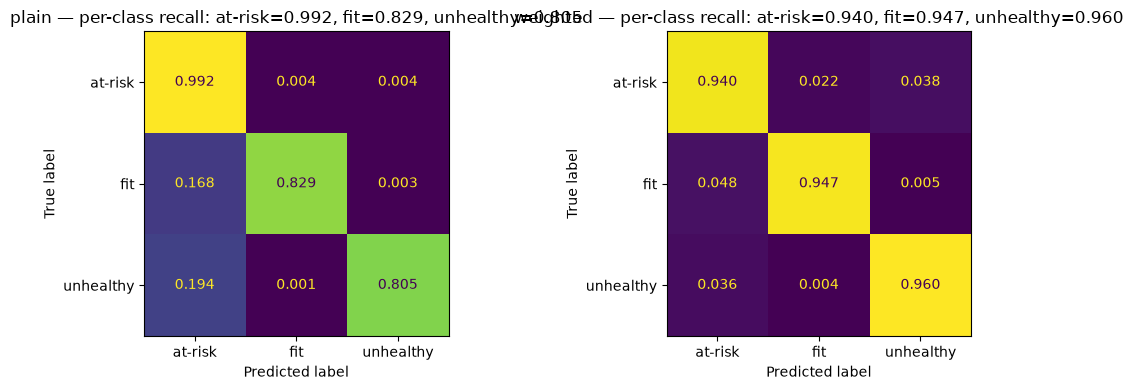

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (oof, title) in zip(axes, [(oof_plain, 'plain'), (oof_w, 'weighted')]):
    cm = confusion_matrix(y, oof.argmax(1), normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, colorbar=False,
                                                            values_format='.3f')
    diag = np.diag(cm)
    ax.set_title(f"{title} — per-class recall: " +
                 ", ".join(f"{c}={r:.3f}" for c, r in zip(CLASSES, diag)))
plt.tight_layout()

**Reading the results:**

| | at-risk | fit | unhealthy | balanced acc. |
|---|---|---|---|---|
| plain | 0.992 | 0.829 | 0.805 | **0.875** |
| weighted | 0.940 | 0.947 | 0.960 | **0.949** |

- The plain model does what its loss tells it: it hoards majority recall (0.992) and starves the minorities. The weighted model **gives back ~5 points of `at-risk` recall to buy ~12–15 points on each minority class** — a terrible trade under plain accuracy, a hugely profitable one under balanced accuracy. Same features, same trees; only the loss weighting changed. *The metric defines the model.*
- **Fold spread is our noise yardstick:** std ≈ 0.0011–0.0017 across folds, so the OOF-level standard error is roughly std/√5 ≈ 0.0005. This is where notebook 03's "keep an experiment only if ΔCV ≥ +0.0005" rule comes from — below that, we're reading tea leaves.
- **A loose end worth noticing:** every weighted fold stopped at `best_iter=1000` — the `n_estimators` cap, meaning early stopping never fired and the model still wanted more trees. Our baseline is slightly *undertrained*. We leave it (it's the fixed reference point), but notebook 04's tuning must raise the cap.

stress_level               4726278.0
sleep_duration             4419213.0
physical_activity_level    1146161.0
bmi                         291546.0
step_count                  156622.0
exercise_duration           154369.0
water_intake                123160.0
calorie_expenditure         120377.0
smoking_alcohol             114075.0
heart_rate                  105528.0
sleep_quality                37862.0
diet_type                    17486.0
gender                       17185.0
dtype: float64

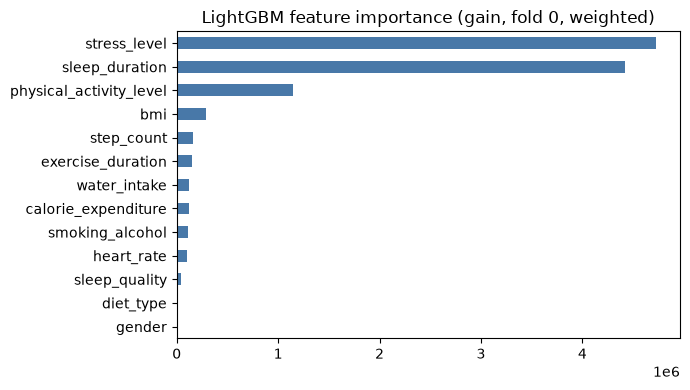

In [8]:
# Feature importance (gain) — cross-check against notebook 01's eyeball ranking.
imp = pd.Series(0.0, index=FEATURES)
model = lgbm_weighted()
tr, va = FOLDS[0]
model.fit(X.iloc[tr], y[tr],
          eval_set=[(X.iloc[va], y[va])],
          callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)])
imp = pd.Series(model.booster_.feature_importance('gain'), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
imp.plot.barh(ax=ax, color='#4878A8')
ax.set_title('LightGBM feature importance (gain, fold 0, weighted)')
plt.tight_layout()
imp.sort_values(ascending=False).round(0)

**Cross-check against notebook 01's eyeball ranking (EDA conclusion #2):** broad agreement — `stress_level` and `sleep_duration` dominate by an order of magnitude, `physical_activity_level` third, then `bmi`; `diet_type` and `gender` are dead last, as the crosstabs predicted. Two instructive wrinkles:

- **`sleep_quality` ranks near the bottom** despite showing clear marginal signal in the EDA. This is the difference between *marginal* and *conditional* importance: gain-importance measures what a feature adds **given the splits already made**, and `stress_level` + `sleep_duration` apparently already carry most of what `sleep_quality` knows. A feature can be genuinely informative yet redundant.
- **`water_intake` and `heart_rate` rank above `sleep_quality`** despite dead-flat class means in the EDA — weak interaction effects that only show up conditionally. Both are reminders that EDA and importances answer *different questions*, and disagreement between them is information, not error.

## 6. CV vs LB — the calibration check

We submit the better variant. The point is not the LB position; it's measuring the CV↔LB gap that turns our OOF score into a *predictor* of leaderboard reality for the rest of the competition.

In [9]:
make_submission(testp_w, '02-lgbm-baseline')

wrote ../submissions/02-lgbm-baseline.csv; prediction distribution:
health_condition
at-risk      0.8158
unhealthy    0.1126
fit          0.0716
Name: proportion, dtype: float64


'../submissions/02-lgbm-baseline.csv'

### Persisting artifacts

We save the OOF and test probabilities plus the fold assignment. **Why:** the OOF matrix is this model's reusable fingerprint — notebook 03 compares experiments against it, and notebook 04 blends models *by their OOF predictions*, which is only valid if every model used the identical fold assignment. Saving `fold_id` per row makes that contract explicit and checkable, rather than relying on "everyone remembered to use seed 42".

In [10]:
import os
os.makedirs('../artifacts', exist_ok=True)
fold_id = np.zeros(len(X), dtype=int)
for k, (tr, va) in enumerate(FOLDS):
    fold_id[va] = k
np.save('../artifacts/fold_id.npy', fold_id)
np.save('../artifacts/oof_lgbm_w.npy', oof_w)
np.save('../artifacts/testp_lgbm_w.npy', testp_w)
print("saved:", os.listdir('../artifacts'))

saved: ['fold_id.npy', 'oof_lgbm_w.npy', 'testp_lgbm_w.npy']


### Result

| submission | CV (OOF bal. acc.) | public LB |
|---|---|---|
| majority baseline (nb 01) | — | 0.33333 |
| LightGBM weighted | **0.94894** | **0.94667** |

**Gap = CV − LB = 0.0023**, CV slightly optimistic. That's tight — consistent with notebook 01's zero-drift finding — and more importantly it's now *measured*. Working rule from here: **decisions are made on CV; the LB is expected to land ≈ 0.002 below it.** If a future submission breaks that pattern by much, we hunt for a bug (leakage in a feature, fold contamination) before celebrating or despairing.

Where we stand: LB top is ≈ 0.953, our near-default weighted LightGBM sits at 0.947. The remaining ~0.006 is the actual competition. Next, notebook 03: feature engineering, run as logged experiments against this baseline.